# **Applied Statistics - Assessment Notebook**

### Authored by Stephen Kerr

---

### **Introduction:**

This notebook contains my analysis of the Iris Dataset which is classic multi-class classification dataset. This flower classification dataset from Fisher, 1936 (see documentation [here](https://archive.ics.uci.edu/dataset/53/iris)) was sourced from **Sckit-learn** `load_iris` (see the documentation [here](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html))

The Iris Dataset is one of the earliest used in literature and is used widely for statistics and machine learning. The Image below illustrates the Three Iris Flower Species and their anatomy (Image sourced from [here](https://thedatafrog.com/en/articles/visualizing-datasets/)).


![iris flower image](images\irish_species_image_data_frog.png) 

### Importing the Dataset

The **`load_iris()`** function loads the Iris dataset. 

The dataset is imported as a *'Bunch'* which is a dictionary like-object with the following attributes: 

| **Attribute** | **Description** |
|---|------|
|**'data'** | which is a pandas Dataframe. |
|**'target'** | which is the classification target. |
|**'feature_name'** | which is a list of the dataset columns. |
|**'target_names'** | which is a list of the target classes. |
| **'target'** | attribute is a pandas Series. |
| **'DESCR'** | which is a string that is a full description of the dataset. |
| **'filename'** | which is a string showing the path to the location of the data. |
| **'frame'** | which is a pandas DataFrame with the combination of data and target. |

Note, the Iris Dataset was loaded with the parameter `'as_frame' = 'True` resulting in an *additional attribute* called `'frame'`. 

### Importing Dependenices 

In [2]:
# import numpy as np
import numpy as np

# import pandas as pd
import pandas as pd

# import matplotlib as plt
import matplotlib.pyplot as plt

# import sklearn as skl
from sklearn.datasets import load_iris

# import Ipython.display as display - to display my tables
from IPython.display import display 

# import seaborn as sns
import seaborn as sns

### Load Iris Dataset

In [3]:
# Load the iris data set.
# Note, used the parameter 'as_frame' = True to get the data in a pandas DataFrame.
iris = load_iris(as_frame=True)

In [4]:
print(f'The Iris Data Set is a {type(iris)}\n')

The Iris Data Set is a <class 'sklearn.utils._bunch.Bunch'>



### **Initialisiong the and defining the Iris DataFrame**

In the Iris dataset, the `'frame'` attribute is a Pandas DataFrame that contains the main source of data. To make the dataset more interpretable, we add a new column called 'species'. This column maps the numerical **'target'** values (0, 1, 2) to their corresponding species names ('setosa', 'versicolor', 'virginica').

We achieve this mapping using the `map()` method (see documentation [here](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.map.html)), which replaces the numerical values in the **'target'** column with their respective species names from the **'target_names'** list creating the new **'species'** column.

Finally, we assign the updated DataFrame to a new variable called `iris_dataframe`, which will be used throughout the analysis.



In [7]:
# To complete the DataFrame we need to add in a 'species' column,
# In order to assign each row to the appropraite species class ['setosa' 'versicolor' 'virginica'],
# We use the map() method the 'target' column of the 'frame' DataFrame and the 'target_names' list,
iris['frame']['species'] = iris['frame']['target'].map({
    0: 'setosa', 
    1: 'versicolor', 
    2: 'virginica'})

# Asigning the 'iris_dataframe' as 'iris['frame'] 
iris_dataframe = iris['frame']

In [15]:
iris_dataframe.head(10)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa
5,5.4,3.9,1.7,0.4,0,setosa
6,4.6,3.4,1.4,0.3,0,setosa
7,5.0,3.4,1.5,0.2,0,setosa
8,4.4,2.9,1.4,0.2,0,setosa
9,4.9,3.1,1.5,0.1,0,setosa


**maybe add in some exploreatory / descriptive analysis of the dataset as awhole**

___
## **Problem 1: Exploring Petal Length**

#### **Assesment Brief:**   
Using the Iris dataset, investigate the distribution of `petal_length`.
1. Plot a histogram showing the petal lengths of all 150 flowers.
2. On the same plot, superimpose an appropriate normal distribution, using the mean and standard deviation calculated from the data.
3. Create separate histograms for each of the three species, and superimpose an appropriate normal distribution on each.
4. Report the mean and standard deviation of petal length for the complete dataset and for each species.
5. Describe and compare the distributions you observe. In particular, discuss whether a normal distribution appears to be a reasonable model for petal length overall and within each species.

#### 1. Histogram of the `petal length`

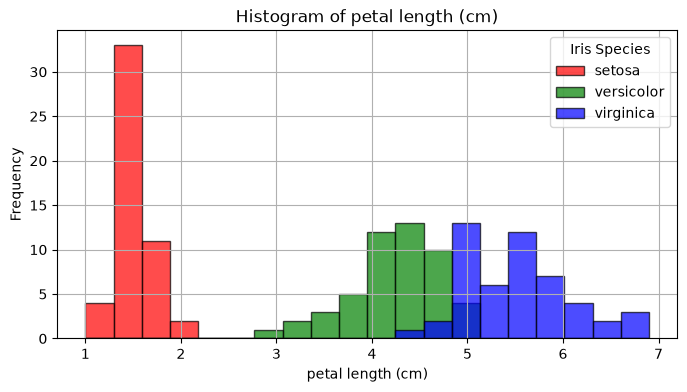

In [18]:
feature = 'petal length (cm)' # define the feature to plot
species = iris_dataframe['species'].unique() # getting the unique species

# define the iris species colours
species_colours = {'setosa': 'red', 'versicolor': 'green', 'virginica': 'blue'}

# shared bin edges so all species use the same bins
bins = np.linspace(iris_dataframe[feature].min(), iris_dataframe[feature].max(), 21)

# Plotting the histogram for the petal_length
plt.figure(figsize=(8, 4)) # set the figure size
for specie in species: # loop through the species
    iris_subset = iris_dataframe[iris_dataframe['species'] == specie] # subset the data by species
    plt.hist(iris_subset[feature], 
                bins=bins, edgecolor='k', alpha=0.7, label=specie, 
                color=species_colours[specie]) # plot the histogram
plt.title(f'Histogram of {feature}') # title of the graph
plt.xlabel(feature) # x-axis label
plt.ylabel('Frequency') # y-axis label
plt.legend(title='Iris Species') # add the legend
plt.grid(True)
plt.show()

# End